In [1]:
import pandas as pd

In [2]:
from sklearn.pipeline import Pipeline

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler,MinMaxScaler

In [4]:
from sklearn.metrics import r2_score

In [5]:
import numpy as np

In [6]:
tira = pd.read_csv(r"C:\Users\Nanda\OneDrive\Documents\Marketting_campaign_performance_prediction\Dataset\tira_campaign_data_with_nulls.csv",encoding_errors="ignore")

In [7]:
numcols = tira.select_dtypes(include="number").columns

In [8]:
tira[numcols] = tira[numcols].fillna(tira[numcols].median())

In [9]:
catcol = tira.select_dtypes(exclude="number").columns

In [10]:
for i in catcol:
    tira[i] = tira[i].fillna(tira[i].mode()[0])

In [11]:
purple = pd.read_csv(r"C:\Users\Nanda\OneDrive\Documents\Marketting_campaign_performance_prediction\Dataset\purplle_campaign_data_with_nulls.csv",encoding_errors="ignore")

In [12]:
numeric = purple.select_dtypes(include="number").columns

In [13]:
categorical = purple.select_dtypes(exclude="number").columns

In [14]:
purple[numeric] = purple[numeric].fillna(purple[numeric].median())

In [15]:
for j in categorical:
    purple[j] = purple[j].fillna(purple[j].mode()[0])

In [16]:
nyka = purple = pd.read_csv(r"C:\Users\Nanda\OneDrive\Documents\Marketting_campaign_performance_prediction\Dataset\nykaa_campaign_data_with_nulls.csv",encoding_errors="ignore")

In [17]:
numericaldata = nyka.select_dtypes(include="number").columns

In [18]:
categoricaldata = nyka.select_dtypes(exclude="number").columns

In [19]:
nyka[numericaldata] = nyka[numericaldata].fillna(nyka[numericaldata].median())

In [20]:
for k in categoricaldata:
    nyka[k] = nyka[k].fillna(nyka[k].mode()[0])

In [21]:
consolidate = pd.concat([nyka,purple,tira], axis=0)

In [22]:
consolidated1= consolidate.copy(deep=True)

In [23]:
consolidated1["CTR"] = consolidated1["Clicks"]/consolidated1["Leads"]

In [24]:
consolidated1["leadRate"] = consolidated1["Leads"]/consolidated1["Clicks"]

In [25]:
consolidated1["converstionrate"] = consolidated1["Conversions"]/consolidated1["Leads"]

In [26]:
from sklearn.model_selection import train_test_split

In [27]:
consolidated1[["Clicks","Leads","Impressions","Conversions"]].corr()["Conversions"]

Clicks         0.773734
Leads          0.869589
Impressions    0.539541
Conversions    1.000000
Name: Conversions, dtype: float64

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

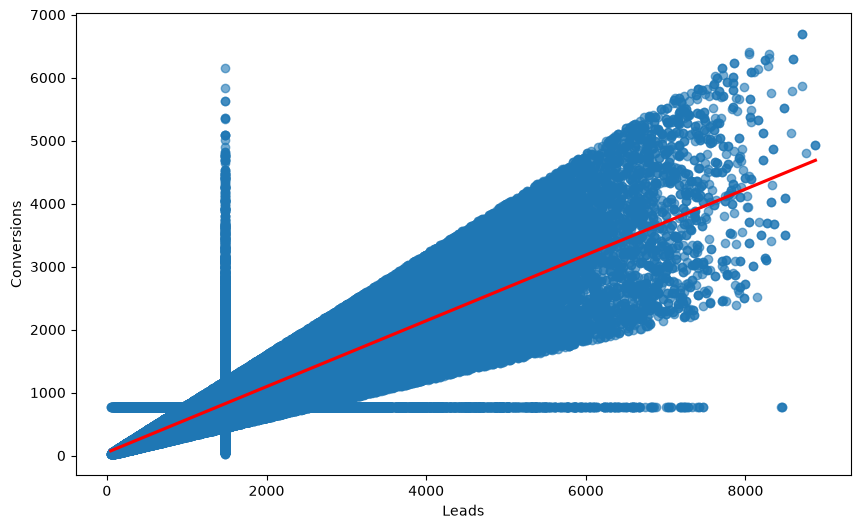

In [29]:
plt.figure(figsize=(10,6))
sns.regplot(
    data=consolidated1,
    x='Leads',
    y='Conversions',
    ci=None,                 # removes confidence interval shading
    scatter_kws={'alpha':0.6},

    line_kws={'color':'red'} # optional: trendline color
)

plt.show()

In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.model_selection import train_test_split

In [31]:
features = consolidated1["Leads"]

In [32]:
outcome = consolidated1["Conversions"]

In [33]:
x_train,x_test,y_train,y_test = train_test_split(features,outcome,test_size=0.2,random_state=42)

In [34]:
lrmodel = Pipeline([
    ("scalar",MinMaxScaler()),
    ("linear",LinearRegression())   
])

In [35]:
lrmodel.fit(x_train.to_frame(),y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scalar', ...), ('linear', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['Leads']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value


In [36]:
y_pred=lrmodel.predict(x_test.to_frame())

In [37]:
from sklearn.metrics import r2_score

In [38]:
score = r2_score(y_pred,y_test)

In [39]:
print(score)

0.6813460067061113


In [40]:
#logistic Regression 

In [41]:
logistic_copy = consolidate.copy(deep=True)

In [42]:
logistic_copy = logistic_copy.drop(["Campaign_ID","Date"],axis=1)

In [43]:
logistic_copy["Engagement_Confirm"] = (logistic_copy["Engagement_Score"] > 10.00).astype(int)

In [44]:
LogisticRegressDataset= logistic_copy[["Impressions","Clicks","Leads","Conversions","Engagement_Confirm"]]

In [45]:
logifeatures = LogisticRegressDataset[["Impressions","Clicks","Leads","Conversions"]]

In [46]:
logitarget = LogisticRegressDataset[["Engagement_Confirm"]]

In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [48]:
logitrain,logitest,classitrain,classitest = train_test_split(logifeatures,logitarget,test_size=0.2,random_state=4)

In [49]:
from sklearn.pipeline import Pipeline

In [50]:
lrmodel = Pipeline([
    ("logistic",LogisticRegression(max_iter=500))
])

In [51]:
lrmodel.fit(logitrain,classitrain)

c:\Users\Nanda\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('logistic', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Impressions','Clicks','Leads','Conversions']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",500
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0


In [52]:
pred = lrmodel.predict(logitest)

In [53]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [54]:
print(accuracy_score(pred,classitest))

0.937629376293763


In [55]:
print(confusion_matrix(pred,classitest))

[[ 9175   949]
 [ 1130 22079]]


In [56]:
print(classification_report(pred,classitest))

              precision    recall  f1-score   support

           0       0.89      0.91      0.90     10124
           1       0.96      0.95      0.96     23209

    accuracy                           0.94     33333
   macro avg       0.92      0.93      0.93     33333
weighted avg       0.94      0.94      0.94     33333



In [57]:
#Decision Tree

In [58]:
DecisonTreeDataset = consolidate.copy(deep=True)

In [59]:
DecisonTreeDataset.drop(["Campaign_ID","Channel_Used","Date"],axis=1)

,Campaign_Type,Target_Audience,Duration,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment
0,Social Media,College Students,21.0,57804.0,6156.0,3616.0,2355.0,1867515.0,207.23,6.14,Hindi,20.98,College Students
1,Paid Ads,Tier 2 City Customers,18.0,91801.0,3321.0,1971.0,1357.0,1046247.0,180.83,3.26,Hindi,7.24,College Students
2,Influencer,Youth,23.0,15536.0,2182.0,952.0,755.0,197055.0,90.60,1.25,English,25.03,College Students
3,Email,Working Women,18.0,88114.0,8413.0,2231.0,947.0,376906.0,249.07,0.60,Hindi,13.15,College Students
4,Paid Ads,College Students,10.0,96871.0,3743.0,2060.0,1258.0,518296.0,228.60,0.80,Hindi,7.29,Tier 2 City Customers
...,...,...,...,...,...,...,...,...,...,...,...,...,...
55550,SEO,Tier 2 City Customers,11.0,54980.0,3799.0,1475.0,1099.0,454986.0,213.21,0.94,Bengali,10.70,Youth
55551,SEO,Working Women,20.0,54886.0,1578.0,634.0,775.0,136514.0,436.24,-0.09,English,4.66,Working Women
55552,Email,Premium Shoppers,13.0,97954.0,11480.0,4567.0,2144.0,445952.0,78.77,1.64,Hindi,18.57,Premium Shoppers
55553,Influencer,Premium Shoppers,22.0,11669.0,3912.0,122.0,44.0,26884.0,208.71,-0.76,English,5.35,Working Women


In [60]:
Engagement_median = DecisonTreeDataset['Engagement_Score'].median()

In [61]:
DTreeDatasettrimmed = DecisonTreeDataset[["Campaign_Type","Target_Audience","Customer_Segment"]]

In [62]:
from sklearn.preprocessing import LabelEncoder

In [63]:
laben = LabelEncoder()

In [64]:
cols = DTreeDatasettrimmed.columns

In [65]:
DTreeDatasettrimmed[cols] = DTreeDatasettrimmed[cols].apply(laben.fit_transform)

In [66]:
DTreeDatasettrimmed["Engagement_Confirm"] = (DecisonTreeDataset["Engagement_Score"]>Engagement_median).astype(int)

In [67]:
DTreeDatasettrimmed

,Campaign_Type,Target_Audience,Customer_Segment,Engagement_Confirm
0,4,0,0,1
1,2,2,0,0
2,1,4,0,1
3,0,3,0,0
4,2,0,2,0
...,...,...,...,...
55550,3,2,4,0
55551,3,3,3,0
55552,0,1,1,1
55553,1,1,3,0


In [68]:
Dfeatures = DTreeDatasettrimmed[["Campaign_Type","Target_Audience","Customer_Segment"]]

In [69]:
Dtarget = DTreeDatasettrimmed[["Engagement_Confirm"]]

In [70]:
dtrain,dtest,ttrain,ttest = train_test_split(Dfeatures,Dtarget,test_size=0.2,random_state=4,stratify=Dtarget)

In [71]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,MinMaxScaler

In [97]:
dtree_model = Pipeline([
    ("scalar",MinMaxScaler()),
    ("decision",DecisionTreeClassifier(splitter= 'best',
 min_samples_split= 5,
 min_samples_leaf= 2,
 max_depth= 5,
 criterion= 'gini')),
])

In [98]:
dtree_model.fit(dtrain,ttrain)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scalar', ...), ('decision', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['Campaign_Type','Target_Audience','Customer_Segment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False


In [99]:
tpred = dtree_model.predict(dtest)

In [100]:
print(accuracy_score(tpred,ttest))

0.5253952539525395


In [101]:

print(classification_report(tpred,ttest))

              precision    recall  f1-score   support

           0       1.00      0.53      0.69     33333
           1       0.00      0.00      0.00         0

    accuracy                           0.53     33333
   macro avg       0.50      0.26      0.34     33333
weighted avg       1.00      0.53      0.69     33333



c:\Users\Nanda\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Nanda\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Nanda\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metri

In [102]:
print(confusion_matrix(tpred,ttest))

[[17513 15820]
 [    0     0]]


In [78]:
#Random Forest

In [79]:
from sklearn.ensemble import RandomForestClassifier

In [80]:
rf_model = Pipeline([
    ("forest",RandomForestClassifier(n_estimators=100,random_state=4))
])

In [81]:
rf_model.fit(dtrain,ttrain)

c:\Users\Nanda\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['Campaign_Type','Target_Audience','Customer_Segment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",4
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'


In [82]:
rf_pred = rf_model.predict(dtest)

In [83]:
print(accuracy_score(rf_pred,ttest))

0.5247952479524796


In [84]:
print(classification_report(rf_pred,ttest))

              precision    recall  f1-score   support

           0       0.90      0.53      0.66     29679
           1       0.11      0.50      0.19      3654

    accuracy                           0.52     33333
   macro avg       0.50      0.51      0.43     33333
weighted avg       0.81      0.52      0.61     33333



In [85]:
print(confusion_matrix(rf_pred,ttest))

[[15676 14003]
 [ 1837  1817]]


In [86]:
#hyperTuning through randomized Search

In [87]:
from sklearn.model_selection import RandomizedSearchCV

In [88]:
params_dist_dt = {
    "decision__max_depth": [None, 5, 10, 20],
    "decision__min_samples_split": [2, 5, 10],
    "decision__min_samples_leaf": [1, 2, 4],
    "decision__criterion": ["gini"],
    "decision__splitter": ["best"]
}

In [89]:
randsearchdt = RandomizedSearchCV(    estimator=dtree_model,
    param_distributions=params_dist_dt,
    cv=3,
    n_jobs=1,
    scoring="accuracy",
    n_iter=10,
    random_state=42)

In [90]:
randsearchdt.fit(dtrain,ttrain)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'decision__criterion': ['gini'], 'decision__max_depth': [None, 5, ...], 'decision__min_samples_leaf': [1, 2, ...], 'decision__min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``Rand

In [91]:
randsearchdtpred =randsearchdt.predict(dtest)

In [92]:
print(accuracy_score(randsearchdtpred,ttest))

0.5253952539525395


In [95]:
randsearchdt.best_params_

{'decision__splitter': 'best',
 'decision__min_samples_split': 5,
 'decision__min_samples_leaf': 2,
 'decision__max_depth': 5,
 'decision__criterion': 'gini'}

In [ ]:
# Implementing hypertuning for XGBoost 

In [103]:
from xgboost import XGBClassifier

In [112]:
pipeline_xgb = Pipeline([
    ('scalar', MinMaxScaler()),
    ('xgb', XGBClassifier(subsample= 0.7,
 n_estimators= 300,
 min_child_weight= 3,
 max_depth= 3,
 learning_rate=0.1,
 gamma=0.2,
 colsample_bytree =0.7))
])

In [107]:
param_dist_xgb = {
    "xgb__n_estimators": [100, 200, 300, 500],
    "xgb__max_depth": [3, 4, 5, 6, 8],
    "xgb__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "xgb__subsample": [0.6, 0.7, 0.8, 1.0],
    "xgb__colsample_bytree": [0.6, 0.7, 0.8, 1.0],
    "xgb__gamma": [0, 0.1, 0.2, 0.5],
    "xgb__min_child_weight": [1, 3, 5]
}

In [108]:
randsearch_xgb = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=param_dist_xgb,
    cv=3,
    n_iter=20,
    scoring="accuracy",
    n_jobs=2,
    random_state=42
)

In [110]:
randsearch_xgb.fit(dtrain,ttrain)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'xgb__colsample_bytree': [0.6, 0.7, ...], 'xgb__gamma': [0, 0.1, ...], 'xgb__learning_rate': [0.01, 0.05, ...], 'xgb__max_depth': [3, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV

In [111]:
randsearch_xgb.best_params_

{'xgb__subsample': 0.7,
 'xgb__n_estimators': 300,
 'xgb__min_child_weight': 3,
 'xgb__max_depth': 3,
 'xgb__learning_rate': 0.1,
 'xgb__gamma': 0.2,
 'xgb__colsample_bytree': 0.7}

In [113]:
pipeline_xgb.fit(dtrain,ttrain)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scalar', ...), ('xgb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['Campaign_Type','Target_Audience','Customer_Segment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False


In [114]:
xgb_pred = pipeline_xgb.predict(dtest)

In [116]:
print(accuracy_score(xgb_pred,ttest))

0.5263852638526385


In [118]:
print(classification_report(xgb_pred,ttest))

              precision    recall  f1-score   support

           0       0.98      0.53      0.68     32558
           1       0.03      0.52      0.05       775

    accuracy                           0.53     33333
   macro avg       0.50      0.52      0.37     33333
weighted avg       0.96      0.53      0.67     33333

